# IBM Quantum Vishnu Institute of Technology

## Qiskit Fall Fest 2026

### Challenge 2: Bias the Quantum Coin

**Objective:** To create a single-qubit quantum circuit with unequal measurement probabilities using Qiskit.

**Tasks:**

1. Create a one-qubit circuit.
2. Apply quantum gates to create a biased measurement distribution.
3. Predict the probabilities before simulation.
4. Execute the circuit for 100 shots.
5. Display a histogram and compare the results with the prediction.


In [1]:
from qiskit import QuantumCircuit

qc = QuantumCircuit(1, 1)

print(qc.draw())

     
  q: 
     
c: 1/
     


In [2]:
qc.h(0)

print(qc.draw())

     ┌───┐
  q: ┤ H ├
     └───┘
c: 1/═════
          


In [3]:
qc = QuantumCircuit(1, 1)

qc.h(0)
qc.z(0)
qc.h(0)

print(qc.draw())

     ┌───┐┌───┐┌───┐
  q: ┤ H ├┤ Z ├┤ H ├
     └───┘└───┘└───┘
c: 1/═══════════════
                    


In [4]:
qc.measure(0, 0)

print(qc.draw())

     ┌───┐┌───┐┌───┐┌─┐
  q: ┤ H ├┤ Z ├┤ H ├┤M├
     └───┘└───┘└───┘└╥┘
c: 1/════════════════╩═
                     0 


In [6]:
from qiskit_aer import AerSimulator

simulator = AerSimulator()

result = simulator.run(qc, shots=100).result()

counts = result.get_counts()

print("Challenge 2 results:", counts)

Challenge 2 results: {'1': 100}


In [7]:
qc_bias0 = QuantumCircuit(1, 1)

qc_bias0.h(0)
qc_bias0.t(0)
qc_bias0.h(0)

print(qc_bias0.draw())

     ┌───┐┌───┐┌───┐
  q: ┤ H ├┤ T ├┤ H ├
     └───┘└───┘└───┘
c: 1/═══════════════
                    


In [8]:
qc_bias0.measure(0, 0)

print(qc_bias0.draw())

     ┌───┐┌───┐┌───┐┌─┐
  q: ┤ H ├┤ T ├┤ H ├┤M├
     └───┘└───┘└───┘└╥┘
c: 1/════════════════╩═
                     0 


In [9]:
result_bias0 = simulator.run(qc_bias0, shots=100).result()

counts_bias0 = result_bias0.get_counts()

print("Biased coin results:", counts_bias0)

Biased coin results: {'1': 21, '0': 79}


In [10]:
qc_bias_s = QuantumCircuit(1, 1)

qc_bias_s.h(0)
qc_bias_s.s(0)
qc_bias_s.h(0)

qc_bias_s.measure(0, 0)

print(qc_bias_s.draw())

     ┌───┐┌───┐┌───┐┌─┐
  q: ┤ H ├┤ S ├┤ H ├┤M├
     └───┘└───┘└───┘└╥┘
c: 1/════════════════╩═
                     0 


In [11]:
result_bias_s = simulator.run(qc_bias_s, shots=100).result()

counts_bias_s = result_bias_s.get_counts()

print("S-gate circuit results:", counts_bias_s)

S-gate circuit results: {'1': 51, '0': 49}


In [14]:
result_a = simulator.run(qc, shots=100).result()
counts_a = result_a.get_counts()

print("H-Z-H results:", counts_a)

H-Z-H results: {'1': 100}


## Challenge 2: Observations and Conclusion

### Observations

1. The H-Z-H circuit produced 100% outcome `1`.
2. The H-T-H circuit produced more `0` outcomes than `1` outcomes.
3. The H-S-H circuit produced approximately equal numbers of `0` and `1` outcomes.
4. The measurement counts may vary slightly for probabilistic circuits because we used only 100 shots.

### Conclusion

Quantum gates can change measurement probabilities by changing the amplitudes and relative phases of a qubit's quantum states. When gates such as H are applied after phase gates such as Z, T, or S, quantum interference can make one outcome more likely than another.

**Answer to the challenge question:** Quantum gates change the probability of obtaining 0 or 1 by manipulating quantum amplitudes and phases. These changes can cause constructive or destructive interference, resulting in different measurement probabilities.


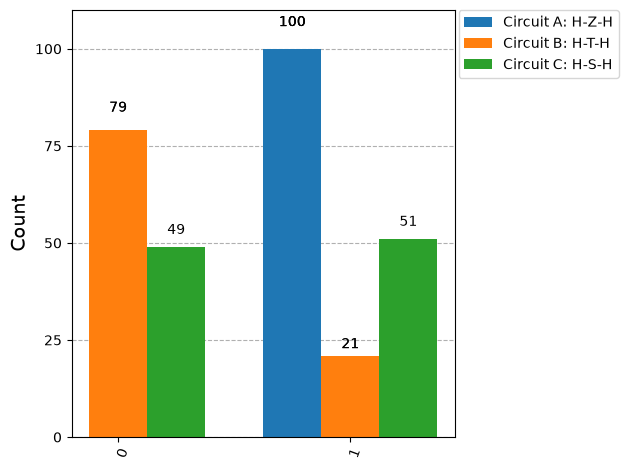

In [15]:
from qiskit.visualization import plot_histogram

plot_histogram(
    [counts_a, counts_bias0, counts_bias_s],
    legend=[
        "Circuit A: H-Z-H",
        "Circuit B: H-T-H",
        "Circuit C: H-S-H"
    ]
)